# P-mediana capacitada: cómo se calcula $f_1$ (accesibilidad)

Este notebook es aparte de `TT.ipynb`. La primera celda copia de ahí el recinto, los módulos y `campo()`, para que corra solo.

La pregunta que contesta $f_1$: **con los módulos ya puestos, ¿cuánto camina en promedio una persona para que la atiendan, si cada módulo atiende a un ritmo limitado?**

In [1]:
# ---------- lo mismo que en TT.ipynb: recinto, módulos y campo() ----------
import numpy as np
import matplotlib.pyplot as plt
import skfmm
from enum import Enum
from dataclasses import dataclass

def pintar(mascara, x, y, ancho, fondo):
    mascara[y:y + fondo, x:x + ancho] = True

def abrir(mascara, x, y, ancho, fondo):
    mascara[y:y + fondo, x:x + ancho] = False

W, H = 200, 120
muros = np.zeros((H, W), dtype=bool)
pintar(muros, 0, 12, W, 1)
for x in (20, 60, 120, 170):
    abrir(muros, x, 12, 8, 1)
pintar(muros, 80, 4, 30, 2)
pintar(muros, 110, 13, 1, H - 13)
abrir(muros, 110, 40, 1, 6)
abrir(muros, 110, 85, 1, 6)
for x in range(12, 110, 12):
    for y in range(25, H, 12):
        pintar(muros, x, y, 1, 1)
pintar(muros, 0, 95, 25, 1)
pintar(muros, 25, 95, 1, H - 95)
abrir(muros, 10, 95, 2, 1)
pintar(muros, 130, 105, 50, 15)
pintar(muros, 194, 40, 6, 20)

class Tipo(Enum):
    #                     nombre              ancho fondo  color     unidades  puerta
    SANITARIO         = ("Sanitarios",          8,   3,  "#4C9BE8",  8,      (0, 8))
    COMIDA            = ("Comida",              5,   5,  "#E8A33D",  4,      (1, 4))
    BEBIDAS           = ("Bebidas",             8,   3,  "#7BC96F",  6,      (0, 8))
    PRIMEROS_AUXILIOS = ("Primeros auxilios",   5,   5,  "#A96BE0",  2,      (2, 3))

    def __init__(self, nombre, ancho, fondo, color, unidades, puerta):
        self.nombre = nombre
        self.ancho = ancho
        self.fondo = fondo
        self.color = color
        self.unidades = unidades
        self.puerta = puerta

@dataclass
class Modulo:
    tipo: Tipo
    x: int
    y: int
    rot: int = 0

    @property
    def ancho(self):
        return self.tipo.ancho if self.rot in (0, 180) else self.tipo.fondo

    @property
    def fondo(self):
        return self.tipo.fondo if self.rot in (0, 180) else self.tipo.ancho

    def celdas_puerta(self):
        a, b = self.tipo.puerta
        x, y, w, f = self.x, self.y, self.ancho, self.fondo
        if self.rot == 0:
            return [(x + u, y - 1) for u in range(a, b)]
        if self.rot == 90:
            return [(x + w, y + u) for u in range(a, b)]
        if self.rot == 180:
            return [(x + w - 1 - u, y + f) for u in range(a, b)]
        if self.rot == 270:
            return [(x - 1, y + f - 1 - u) for u in range(a, b)]

layout = [
    Modulo(Tipo.SANITARIO, 14, 28, 0),
    Modulo(Tipo.SANITARIO, 62, 28, 180),
    Modulo(Tipo.SANITARIO, 150, 30, 0),
    Modulo(Tipo.COMIDA, 38, 64, 90),
    Modulo(Tipo.COMIDA, 86, 64, 270),
    Modulo(Tipo.COMIDA, 140, 70, 0),
    Modulo(Tipo.BEBIDAS, 50, 100, 0),
    Modulo(Tipo.BEBIDAS, 160, 95, 180),
    Modulo(Tipo.PRIMEROS_AUXILIOS, 74, 40, 90),
]

def campo(destino, bloqueado, v=None):
    if v is None:
        v = np.ones((H, W))
    phi = np.ones((H, W))
    phi[destino] = -1
    phi = np.ma.MaskedArray(phi, mask=bloqueado)
    v = np.ma.MaskedArray(np.maximum(v, 1e-3), mask=bloqueado)
    return np.ma.filled(skfmm.travel_time(phi, v, dx=1), np.inf)

ocupado = muros.copy()
for m in layout:
    pintar(ocupado, m.x, m.y, m.ancho, m.fondo)

## 1. El problema

La **p-mediana** tiene dos decisiones:

1. **Dónde** poner las $p$ instalaciones.
2. **Quién va a cuál**: a qué módulo va la gente de cada celda.

En el sistema, la 1 la decide **NSGA-II** (cada layout es una propuesta de dónde) y la 2 la resuelve **$f_1$**, que es lo que hace este notebook.

**Capacitada** quiere decir que cada módulo atiende a lo más cierta parte de la gente. Con los módulos ya puestos, la decisión 2 es un **problema de transporte**:

$$\min \sum_i \sum_j q_i\, d_{ij}\, y_{ij}$$
$$\text{s.a.}\quad \sum_j y_{ij} = 1 \ \ \text{(toda la gente se atiende)} \qquad \sum_i q_i\, y_{ij} \le c_j \ \ \text{(ningún módulo pasa de su capacidad)} \qquad y_{ij} \ge 0$$

| Símbolo | Qué es | En el código |
|---|---|---|
| $i$ | una celda libre (1 m² con gente) | columnas de `d` |
| $j$ | un módulo del tipo que se está viendo | filas de `d` |
| $d_{ij}$ | metros **caminando** de la celda $i$ a la puerta del módulo $j$ (eikonal con $v = 1$) | `d[j, i]` |
| $q_i$ | la parte de la gente que está en la celda $i$; repartida parejo, $q_i = 1/n$ | — |
| $c_j$ | la parte de la gente que puede atender el módulo $j$, según sus **unidades** (inodoros, grifos, puestos) | `cap[j]`, en celdas |
| $y_{ij}$ | qué fracción de la celda $i$ se atiende en $j$ | `asig` |

**¿Por qué fracciones?** Una celda es 1 m² por donde pasa gente durante todo el evento; esa gente sí se reparte entre varios módulos. Además, este tipo de problema siempre tiene un óptimo donde casi todas las celdas van completas a un solo módulo.

**¿Y lo NP-duro?** Lo difícil de la p-mediana es la decisión 1, el *dónde*, y es NP-dura aun sin capacidad (Kariv y Hakimi, 1979). Con los módulos fijos, el transporte es un programa lineal: se resuelve exacto y rápido. O sea, la capacidad no vuelve más difícil lo que calcula $f_1$.

## 2. Distancias: una eikonal por módulo

Para cada módulo, un campo de distancia que arranca en su **puerta**, con muros y los demás módulos como obstáculos. Empezamos con los sanitarios.

In [2]:
tipo = Tipo.SANITARIO
mods = [m for m in layout if m.tipo is tipo]
demanda = ~ocupado                                   # cada celda libre: 1 m² con gente
n = demanda.sum()

def distancia_a(m):
    """Metros caminando desde cada celda hasta la puerta del módulo m."""
    puerta = np.zeros((H, W), dtype=bool)
    for px, py in m.celdas_puerta():
        puerta[py, px] = True
    return campo(puerta, ocupado)

d = np.array([distancia_a(m)[demanda] for m in mods])    # d[j, i]: del módulo j a la celda i
cap = n * np.array([m.tipo.unidades for m in mods]) / sum(m.tipo.unidades for m in mods)
print(d.shape, "= (módulos, celdas)")
print("capacidad de cada módulo, en celdas:", cap.round())

(3, 22467) = (módulos, celdas)
capacidad de cada módulo, en celdas: [7489. 7489. 7489.]


In [3]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Rectangle

colores = ["#8dd3c7", "#fdb462", "#bebada"]          # un color por módulo (hasta 3)

def dibujar(ax, asig, titulo, solo=None):
    """Pinta a qué módulo le toca cada celda. 'solo': máscara de celdas a pintar; el resto, gris."""
    mapa = np.full((H, W), np.nan)
    mapa[demanda] = asig
    if solo is not None:
        mapa[demanda & ~solo] = np.nan
    ax.imshow(np.where(muros, 1, np.nan), origin="lower", extent=(0, W, 0, H), cmap="Greys", vmin=0, vmax=1)
    ax.imshow(mapa, origin="lower", extent=(0, W, 0, H), cmap=ListedColormap(colores[:len(mods)]),
              vmin=-0.5, vmax=len(mods) - 0.5)
    for j, m in enumerate(mods):
        ax.add_patch(Rectangle((m.x, m.y), m.ancho, m.fondo, facecolor=m.tipo.color, edgecolor="black"))
        ax.text(m.x + m.ancho / 2, m.y + m.fondo + 3, str(j), ha="center", fontsize=11, weight="bold")
        px, py = zip(*m.celdas_puerta())
        ax.scatter(np.array(px) + 0.5, np.array(py) + 0.5, s=2, color="black", marker="s")
    ax.set_title(titulo)
    ax.set_facecolor("#eeeeee")

## 3. Sin capacidad: cada celda al más cercano

Es la p-mediana simple. Las regiones que salen son un **Voronoi geodésico**: el Voronoi de siempre, pero midiendo caminando.

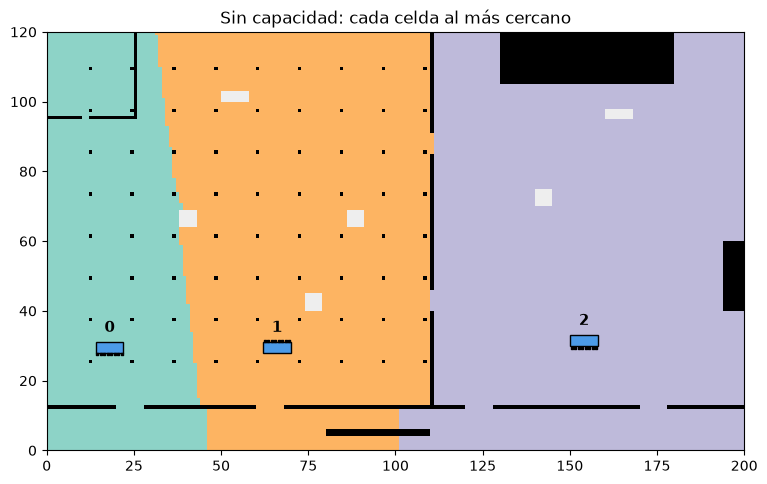

módulo 0:  4504 celdas =  60 % de su capacidad
módulo 1:  8191 celdas = 109 % de su capacidad
módulo 2:  9772 celdas = 130 % de su capacidad
distancia media: 43.1 m


In [4]:
cercano = d.argmin(axis=0)                           # el módulo más cercano a cada celda
carga = np.bincount(cercano, minlength=len(mods))

fig, ax = plt.subplots(figsize=(9, 5.5))
dibujar(ax, cercano, "Sin capacidad: cada celda al más cercano")
plt.show()

for j in range(len(mods)):
    print("módulo %d: %5d celdas = %3.0f %% de su capacidad" % (j, carga[j], 100 * carga[j] / cap[j]))
print("distancia media: %.1f m" % d.min(axis=0).mean())

## 4. Con capacidad: precios, o "filas virtuales"

Cada módulo tiene un **precio** $\pi_j$ en metros, como si fuera una fila: ir a $j$ cuesta $d_{ij} + \pi_j$. Cada celda va a donde le cueste menos.

Un módulo saturado sube su precio hasta que le queda solo la gente que le cabe. **Las primeras en cambiarse son las celdas a las que menos les cuesta**: las que tienen otro módulo casi igual de cerca.

Para cada módulo $j$, con los precios de los demás fijos:

$$\text{margen}_i = \underbrace{\min_{k \ne j}\,(d_{ik} + \pi_k)}_{\text{lo mejor fuera de } j} - \, d_{ij} \qquad \text{(cuántos metros pierde la celda } i \text{ si no la atiende } j)$$

$j$ se queda con las $c_j$ celdas de **mayor margen**, y su precio es el margen de la primera que ya no cabe. Se repite módulo por módulo hasta que nadie se cambia.

**El orden en que se recorren las celdas no importa:** solo cuenta el margen de cada una. Por eso dos layouts iguales dan siempre el mismo $f_1$.

In [5]:
def asignar(d, cap, barridos=50):
    """A qué módulo va cada celda, respetando capacidades. Regresa (asignación, precios, barridos)."""
    m = len(d)
    precio = np.zeros(m)
    if m == 1:
        return np.zeros(d.shape[1], dtype=int), precio, 0
    asig = d.argmin(axis=0)
    for b in range(1, barridos + 1):
        for j in range(m):
            otros = np.delete(d + precio[:, None], j, axis=0).min(axis=0)   # lo mejor fuera de j
            margen = np.sort(otros - d[j])[::-1]                            # de quien más pierde a quien menos
            precio[j] = margen[int(round(cap[j]))]                          # el margen de la primera que no cabe
        precio -= precio.min()                       # solo importan las diferencias: el más barato, en 0
        nueva = (d + precio[:, None]).argmin(axis=0)
        if (nueva == asig).all():
            break
        asig = nueva
    return asig, precio, b

asig, precio, barridos = asignar(d, cap)
carga_c = np.bincount(asig, minlength=len(mods))
print("convergió en %d barridos" % barridos)
for j in range(len(mods)):
    print("módulo %d: precio %5.1f m | %5d celdas = %3.0f %% de su capacidad"
          % (j, precio[j], carga_c[j], 100 * carga_c[j] / cap[j]))
print("distancia media: %.1f m  (sin capacidad: %.1f m)" % (d[asig, np.arange(n)].mean(), d.min(axis=0).mean()))

convergió en 3 barridos
módulo 0: precio   0.0 m |  7489 celdas = 100 % de su capacidad
módulo 1: precio  22.3 m |  7489 celdas = 100 % de su capacidad
módulo 2: precio  54.7 m |  7489 celdas = 100 % de su capacidad
distancia media: 46.4 m  (sin capacidad: 43.1 m)


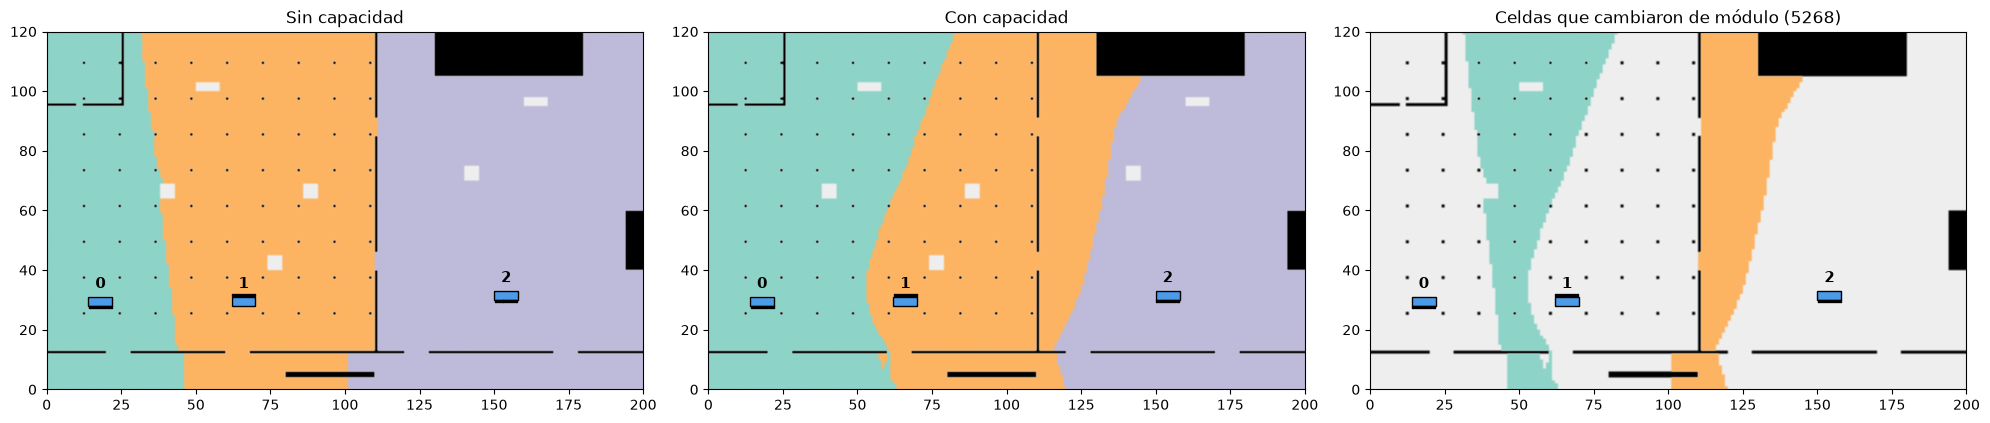

In [6]:
cambio = np.zeros((H, W), dtype=bool)
cambio[demanda] = asig != cercano                    # celdas a las que la capacidad mandó a otro módulo

fig, ax = plt.subplots(1, 3, figsize=(20, 4.5))
dibujar(ax[0], cercano, "Sin capacidad")
dibujar(ax[1], asig, "Con capacidad")
dibujar(ax[2], asig, "Celdas que cambiaron de módulo (%d)" % cambio.sum(), solo=cambio)
plt.tight_layout()
plt.show()

## 5. ¿Es el óptimo? Contra el programa lineal exacto

Resolvemos el mismo transporte con `scipy.optimize.linprog`. Además, las **variables duales** de la restricción de capacidad son justo los precios: el programa lineal dice cuántos metros de "fila" tiene cada módulo.

In [7]:
from scipy.optimize import linprog
from scipy import sparse

m = len(mods)
costo = (d.T / n).ravel()                                     # y[i, j] va en la posición i*m + j
A_eq = sparse.kron(sparse.eye(n), np.ones((1, m)))            # sum_j y_ij = 1
A_ub = sparse.kron(np.ones((1, n)), sparse.eye(m)) / n        # sum_i q_i y_ij <= c_j
r = linprog(costo, A_ub=A_ub, b_ub=cap / n, A_eq=A_eq, b_eq=np.ones(n), bounds=(0, None), method="highs")

duales = -r.ineqlin.marginals                                 # metros por unidad de capacidad
duales -= duales.min()
print("distancia media | programa lineal: %.3f m | precios: %.3f m" % (r.fun, d[asig, np.arange(n)].mean()))
print("precios         | programa lineal:", duales.round(2), "| nuestros:", precio.round(2))

distancia media | programa lineal: 46.430 m | precios: 46.430 m
precios         | programa lineal: [ 0.   22.29 54.7 ] | nuestros: [ 0.   22.29 54.7 ]


## 6. $f_1$ de todo el layout

Se hace lo mismo para cada tipo, y se promedia pesando cada tipo por sus unidades totales (8 inodoros pesan más que 2 puestos de primeros auxilios).

In [8]:
filas, suma, peso_total = [], 0.0, 0.0
for t in Tipo:
    mods = [m for m in layout if m.tipo is t]
    d = np.array([distancia_a(m)[demanda] for m in mods])
    cap = n * np.array([m.tipo.unidades for m in mods]) / sum(m.tipo.unidades for m in mods)
    asig, _, _ = asignar(d, cap)
    con = d[asig, np.arange(n)].mean()
    sin = d.min(axis=0).mean()
    lleno = (np.bincount(d.argmin(axis=0), minlength=len(mods)) / cap).max()
    peso = sum(m.tipo.unidades for m in mods)
    suma += peso * con
    peso_total += peso
    filas.append((t.nombre, len(mods), sin, con, 100 * lleno, peso))

print("%-18s %7s %14s %14s %24s %5s" % ("tipo", "módulos", "sin capacidad", "con capacidad",
                                         "más lleno sin capacidad", "peso"))
for f in filas:
    print("%-18s %7d %12.1f m %12.1f m %22.0f %% %5d" % f)
print("\nf1 = %.1f m" % (suma / peso_total))

tipo               módulos  sin capacidad  con capacidad  más lleno sin capacidad  peso
Sanitarios               3         43.1 m         46.4 m                    130 %    24
Comida                   3         38.9 m         39.8 m                    130 %    12
Bebidas                  2         54.1 m         54.8 m                    113 %    12
Primeros auxilios        1         67.3 m         67.3 m                    100 %     2

f1 = 47.7 m


## 7. Para defenderlo

- **Dónde** van los módulos es lo NP-duro (Kariv y Hakimi, 1979), aun sin capacidad. Eso lo resuelve NSGA-II.
- **Quién va a cuál**, con los módulos fijos, es un programa lineal (transporte). Se resuelve exacto y su resultado no depende del orden de las celdas.
- **Sin capacidad, el optimizador hace trampa.** En 300 layouts factibles del proyecto, el módulo más cargado atendía en mediana el **160 %** de su capacidad (p90: 205 %), y el mejor layout sin capacidad tenía un módulo al **188 %**: caminata corta en papel, fila enorme en la realidad.
- **Único parámetro libre:** la saturación. Aquí vale 1, o sea capacidad total = gente total, y todos los módulos trabajan a tope. Es el caso que más distingue entre layouts; falta un análisis de sensibilidad.

**Diferencias con el proyecto** (`nucleo/acceso.py`): allá la distancia se mide desde todas las celdas libres pegadas al módulo, no solo desde la puerta, y la demanda es la zona ocupable, sin rincones encerrados.

*Kariv, O. y Hakimi, S. L. (1979). An Algorithmic Approach to Network Location Problems. I: The p-Centers / II: The p-Medians. SIAM Journal on Applied Mathematics, 37(3), 513–538 y 539–560.*